# Exploring the labeled decisions

This notebook looks at the first complete dataset of the project: **200,000 real decisions**
from Lichess blitz and rapid games. Each row is one move by one player:

- the position, the player's rating, the time control and both clocks;
- **T**: how many seconds the player took;
- **Y**: whether the move was *acceptable* (it lost at most 5 win-percentage points compared
  with the engine's best move);
- engine-based descriptions of the position: how many moves were acceptable, how far the
  best move stood out, the search depth at which it surfaced, and a category.

**Two things to keep in mind when reading the plots**

1. **The sample is deliberately not representative.** Every 100-point rating band was given
   the same number of rows, so that beginners and masters are equally well covered. Each
   row carries a `sampling_weight` saying how many real decisions it stands for. Statistics
   below use the weights whenever they pool several rating bands; within one band the
   weights matter little.
2. **Clock times are whole seconds** and instant moves (T = 0) were excluded, so T starts
   at 1 and small values are coarse.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from zeitnot.config import REPO_ROOT, get_pipeline_config
from zeitnot.positions.categories import TRAINABLE

cfg = get_pipeline_config()
obs = pl.read_parquet(REPO_ROOT / "data/interim/dev/positions/labeled_observations.parquet")
obs = obs.with_columns((pl.col("mover_elo") // 200 * 200).alias("band"))
print(f"{obs.height:,} decisions, {obs['position_id'].n_unique():,} distinct positions, "
      f"{obs['game_id'].n_unique():,} games")

200,000 decisions, 197,471 distinct positions, 171,684 games


In [2]:
# --- plot style and helpers ---------------------------------------------------
SURFACE, INK, SECONDARY, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CLASS_COLOR = {"blitz": "#2a78d6", "rapid": "#eb6834"}  # fixed: a class always has its color
CATEGORY_COLOR = dict(zip(
    ["tactical", "defensive", "only-move", "quiet", "many-good-moves", "endgame"],
    ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"], strict=True))
RAMP = {"light": "#86b6ef", "mid": "#2a78d6", "dark": "#104281"}  # one hue, ordered
MIN_N = 150  # hide groups with fewer rows: their rates are noise

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": SECONDARY, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "lines.linewidth": 2, "lines.markersize": 5, "legend.frameon": False, "figure.dpi": 110,
})


def wquantile(values: np.ndarray, weights: np.ndarray, q: float) -> float:
    """Weighted quantile: the value below which a share q of the total weight lies."""
    order = np.argsort(values)
    cum = np.cumsum(weights[order])
    return float(values[order][np.searchsorted(cum, q * cum[-1])])


def summarize(df: pl.DataFrame, keys: list[str]) -> pl.DataFrame:
    """Per group: rows, weighted Y and best-move rates, weighted T quantiles."""
    rows = []
    for key, g in df.partition_by(keys, as_dict=True).items():
        w = g["sampling_weight"].to_numpy()
        t = g["time_spent_s"].to_numpy()
        rows.append({
            **dict(zip(keys, key, strict=True)), "n": g.height,
            "y": float(np.average(g["y"].to_numpy(), weights=w)),
            "best": float(np.average(g["is_best"].to_numpy(), weights=w)),
            "t50": wquantile(t, w, 0.5), "t75": wquantile(t, w, 0.75), "t90": wquantile(t, w, 0.9),
            "weight": float(w.sum()),
        })
    return pl.DataFrame(rows).filter(pl.col("n") >= MIN_N).sort(keys)


def end_label(ax, x, y, text, color):
    """Name a line at its right end (the text stays in ink; the mark carries the color)."""
    ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=9, color=SECONDARY)
    ax.plot([x], [y], "o", color=color, markersize=5)


def pct_axis(ax, lo=0.0, hi=1.0):
    ax.set_ylim(lo, hi)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")


balanced = obs.filter(pl.col("position_state") == "balanced")
trainable = balanced.filter(pl.col("category").is_in(TRAINABLE))

## 1. What the sample contains

The left panel shows how many rows we have per rating band; the right panel shows how the
real population is distributed (using the weights). The gap between the two is the reason
the weights exist.

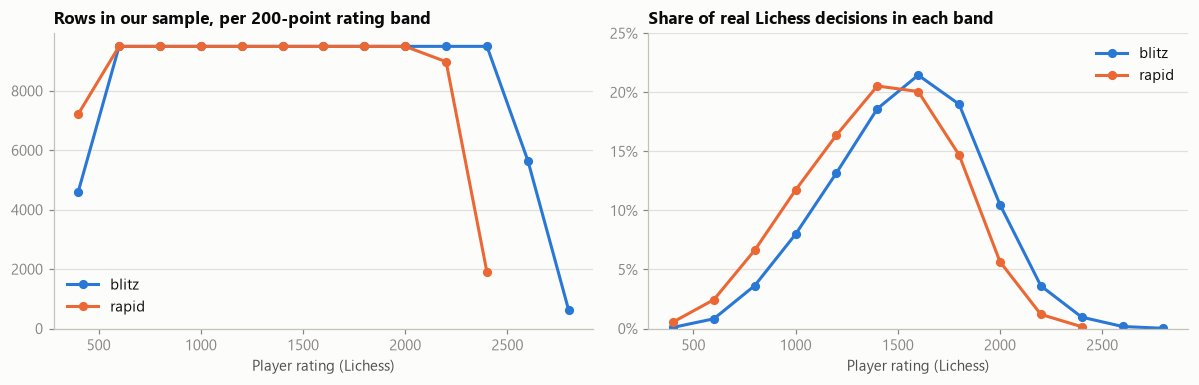

In [3]:
comp = summarize(obs, ["tc_class", "band"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for cls, color in CLASS_COLOR.items():
    d = comp.filter(pl.col("tc_class") == cls)
    axes[0].plot(d["band"], d["n"], "-o", color=color, label=cls)
    axes[1].plot(d["band"], d["weight"] / d["weight"].sum(), "-o", color=color, label=cls)
axes[0].set_title("Rows in our sample, per 200-point rating band")
axes[0].set_ylim(0)
axes[1].set_title("Share of real Lichess decisions in each band")
pct_axis(axes[1], 0, 0.25)
for ax in axes:
    ax.set_xlabel("Player rating (Lichess)")
    ax.legend()
plt.tight_layout()
plt.show()

**Reading it.** The sample is flat by design between about 600 and 2500; only the extreme
bands are thinner, because there we took every decision available. The real population
peaks around 1400–1800. Without the weights, any pooled number would describe a world with
far too many beginners and masters.

## 2. How long do players think?

The curve shows, for each number of seconds, the share of moves played within that time
(population-weighted).

blitz: median 3 s, 75% within 6 s, 90% within 12 s, 99% within 32 s
rapid: median 5 s, 75% within 12 s, 90% within 22 s, 99% within 65 s


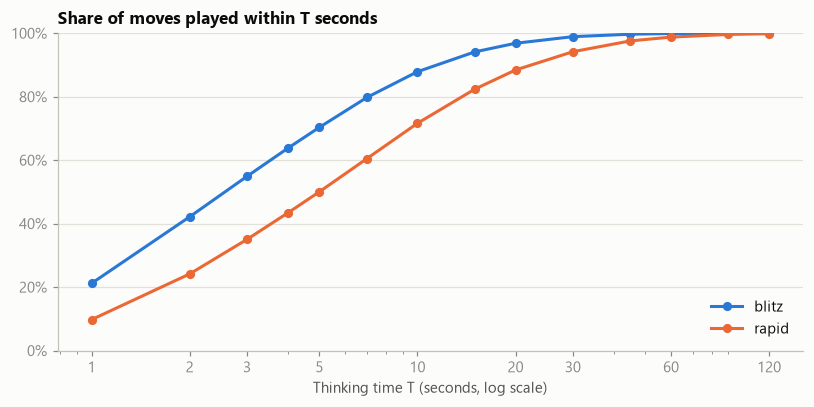

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
grid = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 45, 60, 90, 120])
for cls, color in CLASS_COLOR.items():
    g = obs.filter(pl.col("tc_class") == cls)
    t, w = g["time_spent_s"].to_numpy(), g["sampling_weight"].to_numpy()
    share = [w[t <= s].sum() / w.sum() for s in grid]
    ax.plot(grid, share, "-o", color=color, label=cls)
    med = wquantile(t, w, 0.5)
    print(f"{cls}: median {med:.0f} s, 75% within {wquantile(t, w, .75):.0f} s, "
          f"90% within {wquantile(t, w, .9):.0f} s, 99% within {wquantile(t, w, .99):.0f} s")
ax.set_xscale("log")
ax.set_xticks([1, 2, 3, 5, 10, 20, 30, 60, 120], labels=[1, 2, 3, 5, 10, 20, 30, 60, 120])
ax.set_xlabel("Thinking time T (seconds, log scale)")
ax.set_title("Share of moves played within T seconds")
pct_axis(ax)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Reading it.** Most moves are fast: half are played within a few seconds, and the long
thinks are a thin tail. Rapid is shifted to the right of blitz, as it should be. The
time budgets the Trainer will show therefore live in a narrow range for most positions,
and the interesting cases are the minority where a move takes much longer.

## 3. Thinking time by rating

Three lines per panel: the median move, the slower quarter (75th percentile) and the
slowest tenth (90th percentile).

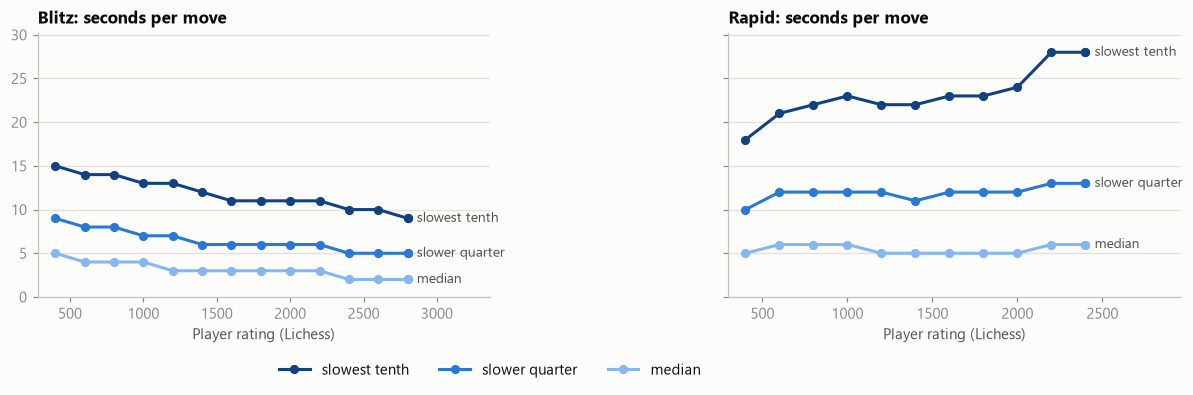

In [5]:
by_band = summarize(obs, ["tc_class", "band"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, cls in zip(axes, CLASS_COLOR, strict=True):
    d = by_band.filter(pl.col("tc_class") == cls)
    for col, shade, name in [("t90", "dark", "slowest tenth"), ("t75", "mid", "slower quarter"),
                             ("t50", "light", "median")]:
        ax.plot(d["band"], d[col], "-o", color=RAMP[shade], label=name)
        end_label(ax, d["band"][-1], d[col][-1], name, RAMP[shade])
    ax.set_title(f"{cls.capitalize()}: seconds per move")
    ax.set_xlabel("Player rating (Lichess)")
    ax.set_xlim(right=d["band"].max() + 560)
    ax.set_ylim(0, by_band["t90"].max() * 1.08)
axes[0].legend(ncols=3, loc="upper center", bbox_to_anchor=(1.0, -0.2))
plt.tight_layout()
plt.show()

**Reading it.** In blitz, stronger players are *faster*: the median and the slow tail both
fall with rating. In rapid the median is flat across ratings, while the slowest tenth of
moves gets *longer* at the top: strong players save their time for the moments that need
it. "How long does a
player at rating R take" is therefore not one number, and it does not simply rise or fall
with strength.

## 4. How often is the move acceptable?

Left: all positions. Right: only *balanced* positions (the mover's winning chances after
the best move are between 10% and 90%).

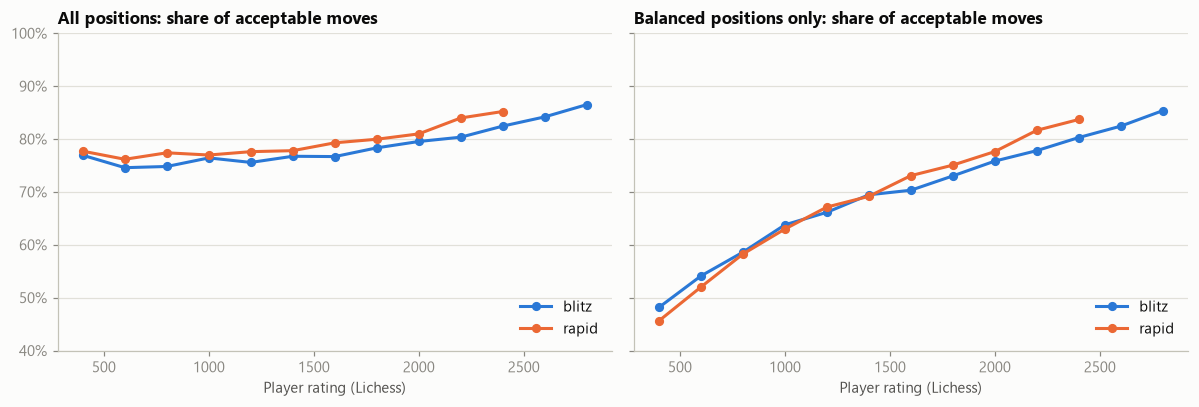

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, df, title in [(axes[0], obs, "All positions"), (axes[1], balanced, "Balanced positions only")]:
    s = summarize(df, ["tc_class", "band"])
    for cls, color in CLASS_COLOR.items():
        d = s.filter(pl.col("tc_class") == cls)
        ax.plot(d["band"], d["y"], "-o", color=color, label=cls)
    ax.set_title(f"{title}: share of acceptable moves")
    ax.set_xlabel("Player rating (Lichess)")
    pct_axis(ax, 0.4, 1.0)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Reading it.** On the left the curve is almost flat for a wide range of ratings, which
looks as if strength hardly mattered. On the right, the same data restricted to balanced
positions rises steadily with rating. The next figure shows why the two differ.

## 5. Why the left panel is flat: decided positions

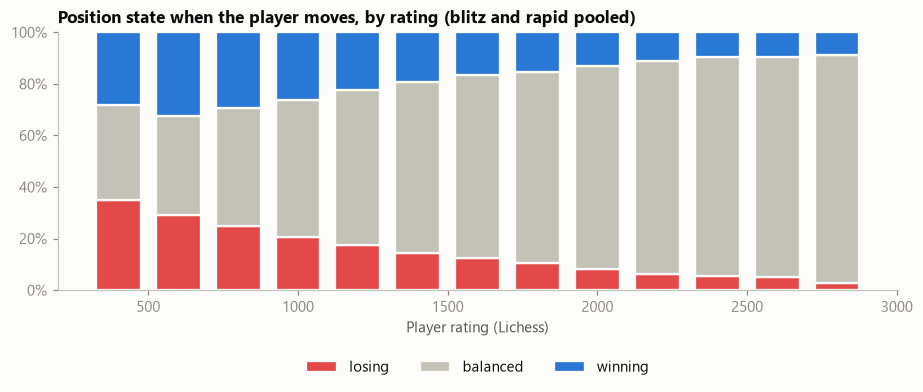

Share of acceptable moves by state (population-weighted):
   balanced: 70.4%
     losing: 98.3%
    winning: 89.1%


In [7]:
state = (obs.group_by("band", "position_state").agg(pl.len().alias("n"))
            .with_columns((pl.col("n") / pl.col("n").sum().over("band")).alias("share"))
            .filter(pl.col("n").sum().over("band") >= MIN_N).sort("band"))
STATE_COLOR = {"winning": "#2a78d6", "balanced": "#c3c2b7", "losing": "#e34948"}
fig, ax = plt.subplots(figsize=(8.5, 3.8))
bands = state["band"].unique().sort().to_list()
bottom = np.zeros(len(bands))
for name in ["losing", "balanced", "winning"]:
    d = dict(state.filter(pl.col("position_state") == name).select("band", "share").iter_rows())
    vals = np.array([d.get(b, 0.0) for b in bands])
    ax.bar(bands, vals, bottom=bottom, width=150, color=STATE_COLOR[name], edgecolor=SURFACE,
           linewidth=1.5, label=name)
    bottom += vals
ax.set_title("Position state when the player moves, by rating (blitz and rapid pooled)")
ax.set_xlabel("Player rating (Lichess)")
pct_axis(ax)
ax.grid(False)
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout()
plt.show()

print("Share of acceptable moves by state (population-weighted):")
for row in summarize(obs, ["position_state"]).iter_rows(named=True):
    print(f"  {row['position_state']:>9}: {row['y']:.1%}")

**Reading it.** Low-rated games are full of positions that are already won or lost, and in
those almost any move is "acceptable": if you are a queen up, most moves keep you winning;
if you are lost, nothing makes it much worse. Pooling them with balanced positions hides
the effect of rating. (This is *Simpson's paradox*: a trend inside each group disappears
when groups with different mixes are combined.) From here on, quality comparisons use
balanced positions only.

## 6. Categories: which kinds of position are hard?

Each position has a rule-based category. *Tactical*, *defensive* and *only-move* positions
have just one or two acceptable moves; *many-good-moves* positions have at least four.

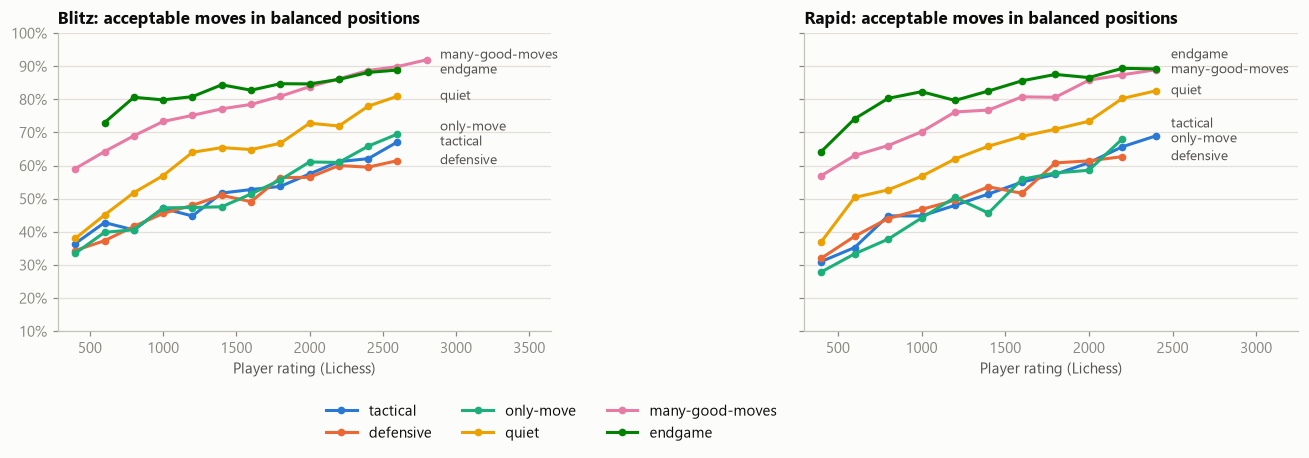

In [8]:
cat = summarize(trainable, ["tc_class", "category", "band"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, cls in zip(axes, CLASS_COLOR, strict=True):
    ends = []
    for name, color in CATEGORY_COLOR.items():
        d = cat.filter((pl.col("tc_class") == cls) & (pl.col("category") == name))
        ax.plot(d["band"], d["y"], "-o", color=color, label=name, markersize=4)
        ends.append((d["y"][-1], d["band"][-1], name, color))
    # direct labels in one column right of the last point, nudged apart so they do not overlap
    x_label = max(x for _, x, _, _ in ends) + 90
    last_y = None
    for y, x, name, color in sorted(ends):
        y_text = y if last_y is None or y - last_y > 0.045 else last_y + 0.045
        ax.annotate(name, (x, y), xytext=(x_label, y_text), fontsize=9, color=SECONDARY, va="center")
        last_y = y_text
    ax.set_title(f"{cls.capitalize()}: acceptable moves in balanced positions")
    ax.set_xlabel("Player rating (Lichess)")
    ax.set_xlim(right=x_label + 760)
    pct_axis(ax, 0.1, 1.0)
axes[0].legend(ncols=3, loc="upper center", bbox_to_anchor=(1.0, -0.2))
plt.tight_layout()
plt.show()

**Reading it.** The categories separate cleanly and keep their order at every rating: the
sharp categories are hardest, quiet positions are in between, and positions with many good
moves or calm endgames are easiest. Every line rises with rating, and blitz and rapid look
alike. The sharp categories also show the steepest rise, so that is where strength matters
most.

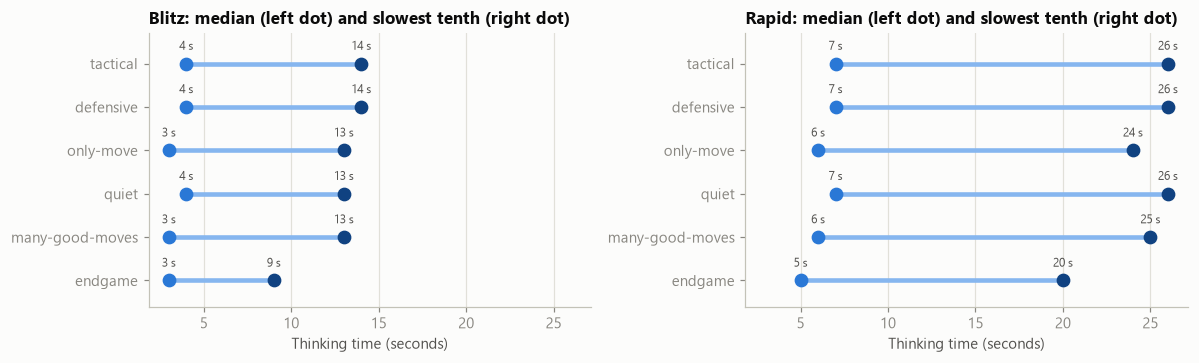

In [9]:
tcat = summarize(trainable, ["tc_class", "category"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
order = ["tactical", "defensive", "only-move", "quiet", "many-good-moves", "endgame"]
for ax, cls in zip(axes, CLASS_COLOR, strict=True):
    d = {r["category"]: r for r in tcat.filter(pl.col("tc_class") == cls).iter_rows(named=True)}
    for i, name in enumerate(order[::-1]):
        ax.plot([d[name]["t50"], d[name]["t90"]], [i, i], color=RAMP["light"], linewidth=3)
        ax.plot(d[name]["t50"], i, "o", color=RAMP["mid"], markersize=8)
        ax.plot(d[name]["t90"], i, "o", color=RAMP["dark"], markersize=8)
        ax.annotate(f"{d[name]['t50']:.0f} s", (d[name]["t50"], i), xytext=(0, 9),
                    textcoords="offset points", ha="center", fontsize=8, color=SECONDARY)
        ax.annotate(f"{d[name]['t90']:.0f} s", (d[name]["t90"], i), xytext=(0, 9),
                    textcoords="offset points", ha="center", fontsize=8, color=SECONDARY)
    ax.set_yticks(range(len(order)), order[::-1])
    ax.set_ylim(-0.6, len(order) - 0.3)
    ax.set_title(f"{cls.capitalize()}: median (left dot) and slowest tenth (right dot)")
    ax.set_xlabel("Thinking time (seconds)")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
plt.tight_layout()
plt.show()

**Reading it.** Thinking time differs far less between categories than move quality does.
Players spend only slightly longer in sharp positions than in easy ones, although they get
them wrong far more often. That is the weakness this project is about: not recognizing that
a moment needs more time.

## 7. The clock

How do time and quality change as the clock runs down? The horizontal axis is the share of
the starting time still on the player's clock.

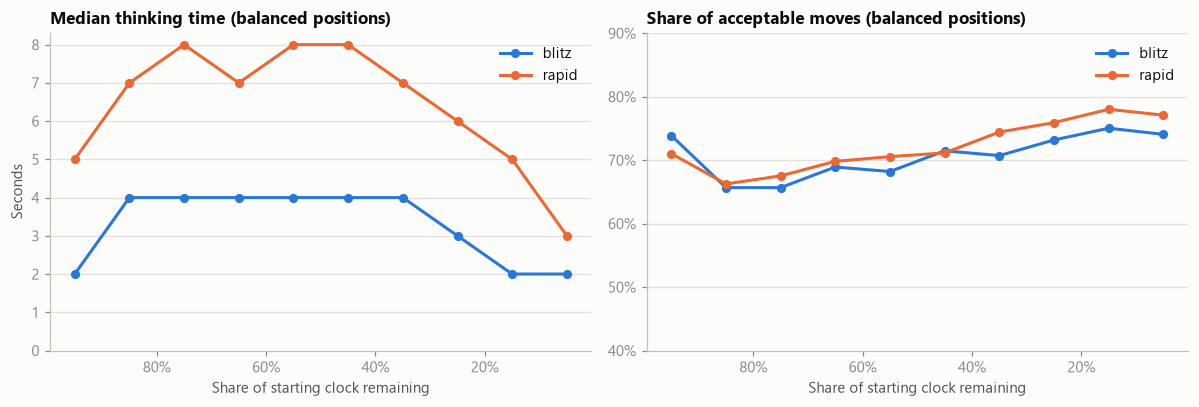

In [10]:
clock = balanced.with_columns(
    (pl.col("own_clk_before_s") / pl.col("base_s")).clip(0, 1).alias("left")
).with_columns((pl.col("left") * 10).floor().clip(0, 9).truediv(10).alias("bin"))
cs = summarize(clock, ["tc_class", "bin"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for cls, color in CLASS_COLOR.items():
    d = cs.filter(pl.col("tc_class") == cls)
    x = d["bin"] + 0.05
    axes[0].plot(x, d["t50"], "-o", color=color, label=cls)
    axes[1].plot(x, d["y"], "-o", color=color, label=cls)
axes[0].set_title("Median thinking time (balanced positions)")
axes[0].set_ylabel("Seconds")
axes[0].set_ylim(0)
axes[1].set_title("Share of acceptable moves (balanced positions)")
pct_axis(axes[1], 0.4, 0.9)
for ax in axes:
    ax.set_xlabel("Share of starting clock remaining")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.invert_xaxis()  # the game runs left to right
    ax.legend()
plt.tight_layout()
plt.show()

**Reading it.** Read each panel from left (full clock) to right (almost none). Thinking
time drops as the clock runs down, as expected. Move quality does **not** drop: it rises.
That is not time pressure making players better. The clock is tied up with the stage of
the game: a low clock usually means a late position, and late positions in this sample
are easier (many calm endgames). So this figure describes what happens along a game; it
does not isolate the effect of time pressure. The model will separate the two by taking
the clock and the position as separate inputs.

## 8. Do longer thinks give better moves?

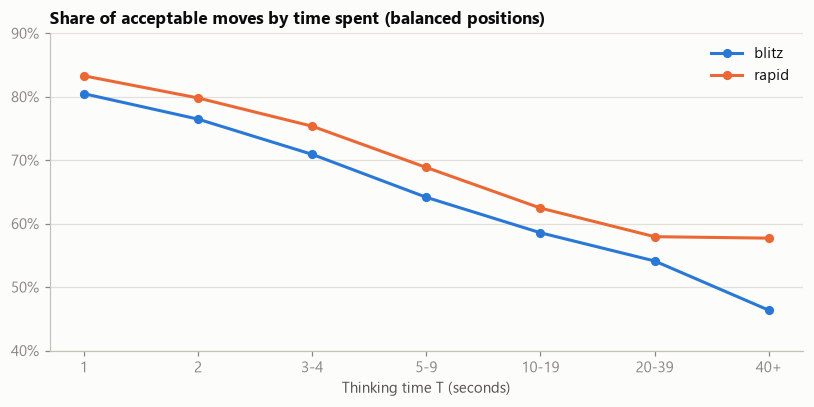

In [11]:
edges, labels = [2, 3, 5, 10, 20, 40], ["1", "2", "3-4", "5-9", "10-19", "20-39", "40+"]
sa = balanced.with_columns(
    pl.col("time_spent_s").cut(edges, labels=labels, left_closed=True).alias("t_bin"))
ss = summarize(sa, ["tc_class", "t_bin"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for cls, color in CLASS_COLOR.items():
    d = {r["t_bin"]: r["y"] for r in ss.filter(pl.col("tc_class") == cls).iter_rows(named=True)}
    ax.plot(range(len(labels)), [d.get(k, np.nan) for k in labels], "-o", color=color, label=cls)
ax.set_xticks(range(len(labels)), labels)
ax.set_xlabel("Thinking time T (seconds)")
ax.set_title("Share of acceptable moves by time spent (balanced positions)")
pct_axis(ax, 0.4, 0.9)
ax.legend()
plt.tight_layout()
plt.show()

**Reading it.** Moves that took longer are *less* often acceptable. That does not mean
thinking hurts: players think longer precisely when the position is hard, so long thinks
are concentrated on the positions where mistakes are likely. This is the same confounding
that made "T after a long think" misleading earlier, and it is why time and move quality
have to be modeled together, with the position's difficulty as an input.

## 9. Do the engine's difficulty signals mean anything to humans?

Three descriptions of a position that come from the engine alone: how many of the top five
moves are acceptable, how far the best move stands out, and the search depth at which the
best move first came out on top (a move found at depth 1 is obvious; one that needs
depth 10 is not).

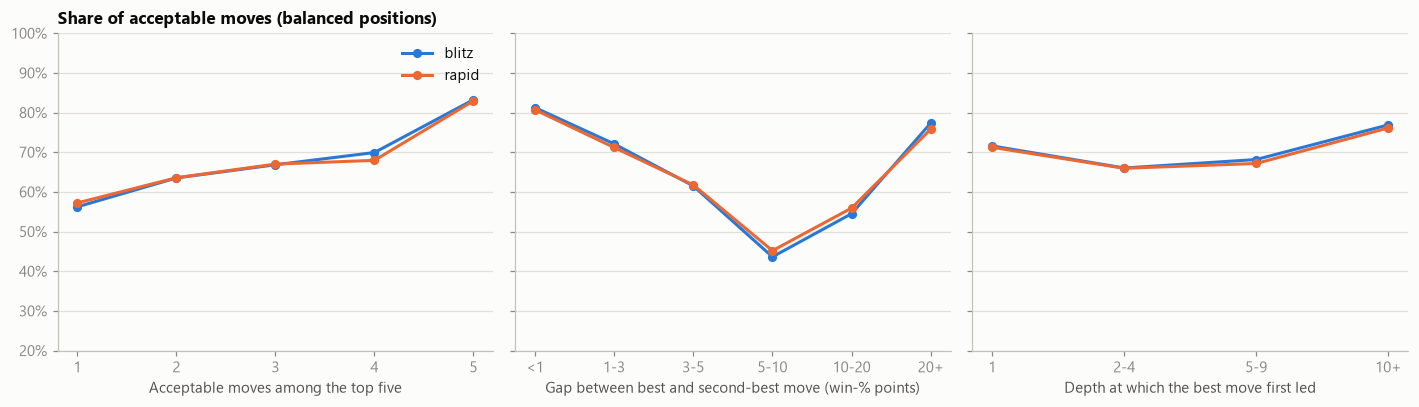

In [12]:
sig = balanced.filter(pl.col("n_legal_moves") > 1).with_columns(
    pl.col("best_move_first_depth").cut([2, 5, 10], labels=["1", "2-4", "5-9", "10+"],
                                         left_closed=True).alias("depth_bin"),
    pl.col("gap_1_2").cut([1, 3, 5, 10, 20], labels=["<1", "1-3", "3-5", "5-10", "10-20", "20+"],
                          left_closed=True).alias("gap_bin"),
)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
specs = [("n_acceptable_lines", [1, 2, 3, 4, 5], "Acceptable moves among the top five"),
         ("gap_bin", ["<1", "1-3", "3-5", "5-10", "10-20", "20+"],
          "Gap between best and second-best move (win-% points)"),
         ("depth_bin", ["1", "2-4", "5-9", "10+"], "Depth at which the best move first led")]
for ax, (col, keys, xlabel) in zip(axes, specs, strict=True):
    s = summarize(sig.filter(pl.col(col).is_not_null()), ["tc_class", col])
    for cls, color in CLASS_COLOR.items():
        d = {r[col]: r["y"] for r in s.filter(pl.col("tc_class") == cls).iter_rows(named=True)}
        ax.plot(range(len(keys)), [d.get(k, np.nan) for k in keys], "-o", color=color, label=cls)
    ax.set_xticks(range(len(keys)), [str(k) for k in keys])
    ax.set_xlabel(xlabel)
    pct_axis(ax, 0.2, 1.0)
axes[0].set_title("Share of acceptable moves (balanced positions)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Reading it.**

- *Left:* the fewer acceptable moves a position has, the less often players find one. A
  clear, monotone difficulty signal.
- *Middle:* **not** monotone. Positions where the best move is only moderately better than
  the second (5-10 points) are the hardest. When the gap is huge (20 points or more), the
  best move is usually obvious, such as taking a piece left hanging, and players find it
  most of the time. A big gap means "this moment matters", not "this move is hard to see".
- *Right:* the depth signal alone says little. It mixes positions with one deep, hidden
  move and quiet positions where the engine keeps switching between equally good moves.

No single engine number measures human difficulty; the model will need them in
combination, together with the player's rating.

## 10. Moves that were prepared earlier

A player often works out a sequence during one long think and then plays the follow-up
moves quickly. Recaptures are the clearest case.

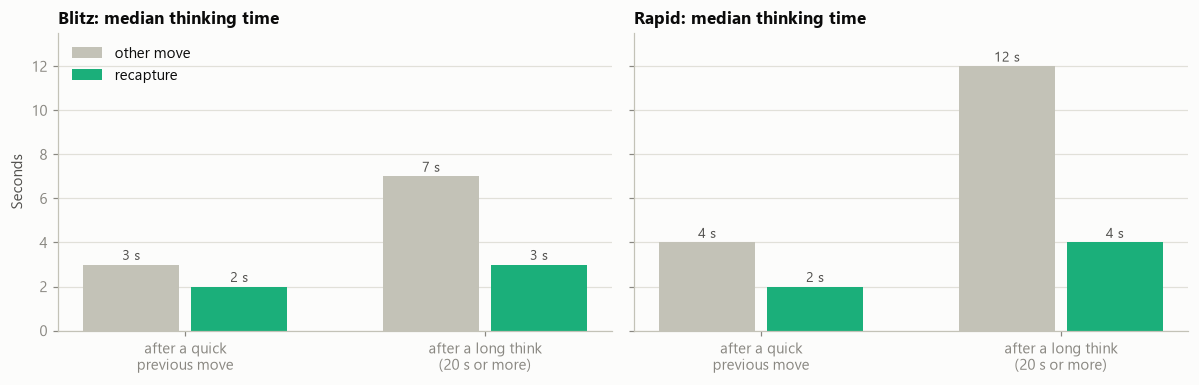

In [13]:
prep = obs.filter(pl.col("prev_own_time_spent_s").is_not_null()).with_columns(
    pl.when(pl.col("prev_own_time_spent_s") >= 20).then(pl.lit("after a think of 20 s or more"))
    .when(pl.col("prev_own_time_spent_s") < 5).then(pl.lit("after a quick previous move (< 5 s)"))
    .alias("prev"),
    pl.when(pl.col("is_recapture")).then(pl.lit("recapture")).otherwise(pl.lit("other move"))
    .alias("kind"),
).filter(pl.col("prev").is_not_null())
ps = summarize(prep, ["tc_class", "prev", "kind"])
groups = ["after a quick previous move (< 5 s)", "after a think of 20 s or more"]
KIND_COLOR = {"other move": "#c3c2b7", "recapture": "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, cls in zip(axes, CLASS_COLOR, strict=True):
    d = {(r["prev"], r["kind"]): r["t50"] for r in ps.filter(pl.col("tc_class") == cls).iter_rows(named=True)}
    for j, (kind, color) in enumerate(KIND_COLOR.items()):
        xs = np.arange(len(groups)) + (j - 0.5) * 0.36
        vals = [d.get((g, kind), np.nan) for g in groups]
        ax.bar(xs, vals, width=0.32, color=color, label=kind)
        for x, v in zip(xs, vals, strict=True):
            ax.annotate(f"{v:.0f} s", (x, v), xytext=(0, 3), textcoords="offset points",
                        ha="center", fontsize=9, color=SECONDARY)
    ax.set_xticks(range(len(groups)), ["after a quick\nprevious move", "after a long think\n(20 s or more)"])
    ax.set_title(f"{cls.capitalize()}: median thinking time")
    ax.set_ylim(0, 13.5)
axes[0].set_ylabel("Seconds")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Reading it.** After a long think, an ordinary move is slow again (hard phases last several
moves), but a recapture is quick: it was already decided. A training position shows the
player a position cold, with no such preparation, so budgets must describe a player seeing
the position fresh. These context columns are what will let the model make that correction.

## 11. Consistency checks

Each line must print `ok`. They restate, as assertions, properties the dataset should have.

In [14]:
def check(name: str, condition: bool) -> None:
    print(f"{'ok  ' if condition else 'FAIL'}  {name}")
    assert condition, name


check("200,000 decisions, each with a label", obs.height == 200_000 and obs["loss_win_pct"].null_count() == 0)
check("no first moves, premoves or missing times", obs["time_spent_s"].min() >= 1)
check("every decision is from blitz or rapid", set(obs["tc_class"].unique()) == {"blitz", "rapid"})
check("ratings cover 400 to 3000+", obs["mover_elo"].min() < 500 and obs["mover_elo"].max() >= 3000)
# A played move searched on its own can score above the "best" line: all of the second
# search's effort goes into one move, so it sometimes sees further (for example a forced
# mate in a trivially won endgame that the five-line search rated as "a big advantage").
check("played move scores more than 1 point above the best line in under 0.1% of rows",
      (obs["loss_win_pct"] < -1).mean() < 0.001)
check("... and more than 5 points above it in under 0.01% of rows",
      (obs["loss_win_pct"] < -5).mean() < 0.0001)
check("a best move always counts as acceptable", obs.filter(pl.col("is_best"))["y"].all())
check("a forced move is always acceptable", obs.filter(pl.col("n_legal_moves") == 1)["y"].all())

bb = summarize(balanced, ["tc_class", "band"]).filter(pl.col("n") >= 1000)
for cls in CLASS_COLOR:
    ys = bb.filter(pl.col("tc_class") == cls)["y"].to_numpy()
    check(f"{cls}: acceptable-move rate rises with rating in balanced positions",
          bool(np.all(np.diff(ys) > -0.01)) and ys[-1] - ys[0] > 0.25)

med = {r["tc_class"]: r["t50"] for r in summarize(obs, ["tc_class"]).iter_rows(named=True)}
check("rapid moves take longer than blitz moves", med["rapid"] > med["blitz"])
cat_y = {r["category"]: r["y"] for r in summarize(trainable, ["category"]).iter_rows(named=True)}
check("sharp categories are harder than quiet, quiet harder than many-good-moves",
      max(cat_y["tactical"], cat_y["defensive"], cat_y["only-move"]) < cat_y["quiet"] < cat_y["many-good-moves"])

ok    200,000 decisions, each with a label
ok    no first moves, premoves or missing times
ok    every decision is from blitz or rapid
ok    ratings cover 400 to 3000+
ok    played move scores more than 1 point above the best line in under 0.1% of rows
ok    ... and more than 5 points above it in under 0.01% of rows
ok    a best move always counts as acceptable
ok    a forced move is always acceptable
ok    blitz: acceptable-move rate rises with rating in balanced positions
ok    rapid: acceptable-move rate rises with rating in balanced positions
ok    rapid moves take longer than blitz moves
ok    sharp categories are harder than quiet, quiet harder than many-good-moves


## What this means for the next steps

- The data behaves the way chess does: quality rises with rating, sharp positions are
  hard, slower time controls give more time per move.
- Thinking time alone says little about difficulty; **time and move quality must be modeled
  together**, with the position's state and difficulty signals as inputs.
- Players barely slow down in sharp positions. A budget that tells a player "this one
  deserves 20 seconds" is exactly the feedback that is missing.
- Caveat: this sample comes from the first days of two months, so it is suitable for
  building and testing the pipeline and first models, not yet for final numbers.